<div style="text-align: center;">
<h1>Clustering Consumer Insurance Questions</h1>
<h3>DATASCI 530 Project 3</h3>
<p>Maxine Hakimi-Bulson</p>
</div>

## Introduction

Insurance questions cover a range of topics, from health coverage to retirement planning. This project explores whether text clustering can organize these questions into meaningful groups without using their existing category labels.

Using the InsuranceQA dataset, I analyze 16,865 unique questions across 12 insurance categories. I use CountVectorizer to convert the questions into a matrix of word counts to represent word frequencies, TruncatedSVD to reduce this matrix to a smaller number of features, and MiniBatchKMeans to group questions with similar vocabulary. The original categories are retained to help interpret and evaluate the resulting clusters.

This project uses InsuranceQA, a research dataset of questions collected from Insurance Library. It examines the **research question: How well can unsupervised text clustering organize consumer insurance questions, and how do the resulting groups relate to the existing insurance categories?**

The model uses question text to discover groups without receiving the existing category labels. Those labels are retained for later evaluation and interpretation.

## Key Findings

- The analysis used 16,865 unique insurance questions across 12 existing categories.
- The selected model used 25 SVD components and 15 clusters.
- On unseen test questions, the model achieved a silhouette score of 0.476 and an adjusted Rand index of 0.796 against the existing categories.
- Most clusters reflected recognizable insurance topics, but some divided similar wording into separate groups or combined multiple subjects.

## Data Source

InsuranceQA was introduced by Feng and colleagues for research on insurance question answering. Its documentation reports 16,889 questions across training, validation, and test partitions.

I use the Version 2 question file and its vocabulary file. The questions are stored as encoded word identifiers, which the vocabulary file translates into readable text. Each record also has an insurance category and identifiers for relevant answers.

This project analyzes the questions rather than building a question-answering system. Answer identifiers are excluded, and category labels are not used as clustering inputs.

Source: [InsuranceQA repository](https://github.com/shuzi/insuranceQA)

Reference: Feng, M., Xiang, B., Glass, M. R., Wang, L., and Zhou, B. (2015). *Applying Deep Learning to Answer Selection: A Study and an Open Task.*

## Import Packages and Load Data

I use pandas to load and organize the data and scikit-learn to divide it into training, validation, and test sets. I load the InsuranceQA questions and vocabulary files into pandas. The vocabulary translates encoded word identifiers into readable questions. I retain the question text and original insurance category for the analysis.

In [53]:
# Import packages for data preparation and splitting.
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from IPython.display import display, HTML

# Read the encoded questions and vocabulary.
questions = pd.read_csv(
    "insuranceqa_data/InsuranceQA.question.anslabel.token.encoded.gz",
    sep="\t",
    header=None,
    names=["category", "encoded_question", "answer_ids"]
)

vocabulary = pd.read_csv(
    "insuranceqa_data/vocabulary.txt",
    sep="\t",
    header=None,
    names=["token", "word"],
    keep_default_na=False,
    quoting=3
)

# Translate the encoded tokens into words.
word_lookup = vocabulary.set_index("token")["word"].to_dict()

questions["question"] = questions["encoded_question"].apply(
    lambda text: " ".join(
        word_lookup[token] for token in text.split()
    )
)

questions = questions[["category", "question"]].copy()

# Check if loaded correctly
#display(questions.head())

### Check Missing Values and Duplicates

I check for missing or blank questions and categories, repeated question texts, and conflicting category labels. Duplicate detection ignores capitalization and extra whitespace.

In [54]:
# Standardize capitalization and spacing to identify duplicates.
questions["question_key"] = (
    questions["question"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

category_counts = (
    questions.groupby("question_key")["category"].nunique()
)

quality_summary = pd.DataFrame({
    "Check": [
        "Question records",
        "Insurance categories",
        "Missing or blank questions",
        "Missing or blank categories",
        "Repeated questions",
        "Questions with conflicting categories"
    ],
    "Count": [
        len(questions),
        questions["category"].nunique(),
        (
            questions["question"].isna()
            | questions["question_key"].eq("")
        ).sum(),
        (
            questions["category"].isna()
            | questions["category"].str.strip().eq("")
        ).sum(),
        questions["question_key"].duplicated().sum(),
        category_counts.gt(1).sum()
    ]
})

display(quality_summary)

,Check,Count
0,Question records,16889
1,Insurance categories,12
2,Missing or blank questions,0
3,Missing or blank categories,0
4,Repeated questions,24
5,Questions with conflicting categories,0


### Remove Repeated Questions

The checks identified 24 repeated questions with no conflicting category labels. I keep the first occurrence of each standardized question, leaving 16,865 unique questions. Removing duplicates before splitting prevents identical questions from appearing in different datasets.

In [55]:
# Keep the first occurrence of each standardized question.
questions_clean = (
    questions.drop_duplicates("question_key")
    .reset_index(drop=True)
)

display(questions_clean.shape)

(16865, 3)

### Summary Statistics

I calculate the number and percentage of questions in each insurance category to describe the dataset. These labels will help interpret the clusters later but will not be used as model inputs.

In [56]:
category_summary = (
    questions_clean["category"]
    .value_counts()
    .rename_axis("Insurance category")
    .reset_index(name="Questions")
)

category_summary["Percent"] = (
    100 * category_summary["Questions"] / len(questions_clean)
).round(1)

### Figure 1. Insurance Categories by Number of Questions

Category labels are sized according to their number of unique questions. Larger labels represent more common categories. The cloud illustrates category imbalance; exact counts are reported in the category-summary table.

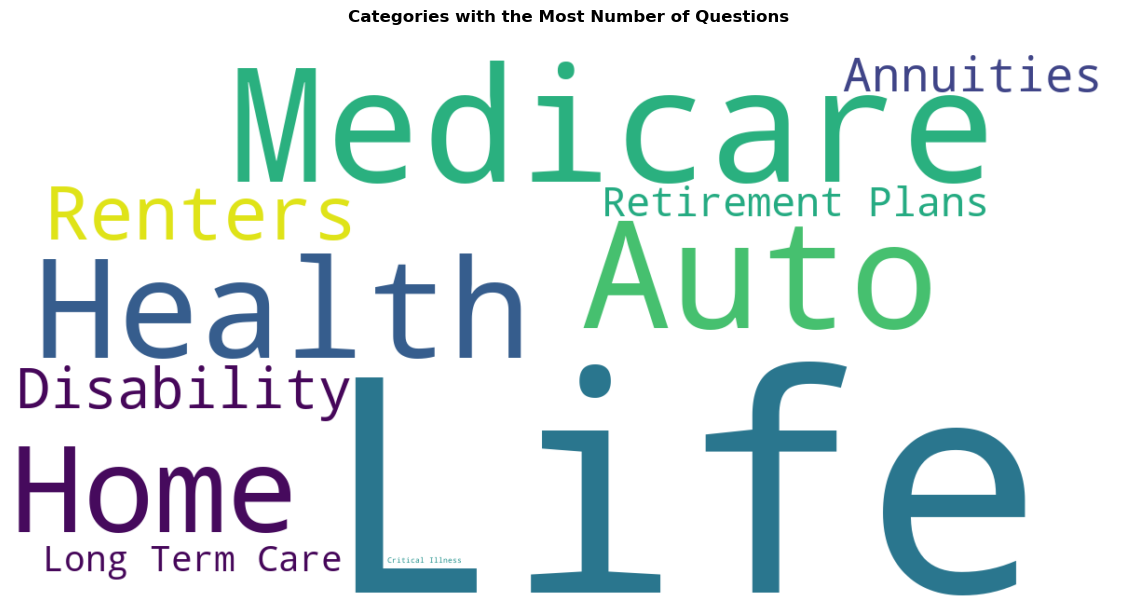

In [57]:
from wordcloud import WordCloud

# Size category labels by their number of unique questions.
category_labels = (
    category_summary["Insurance category"]
    .str.replace("-insurance", "", regex=False)
    .str.replace("-", " ", regex=False)
    .str.title()
)

category_frequencies = dict(zip(
    category_labels,
    category_summary["Questions"]
))

cloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis",
    relative_scaling=1,
    prefer_horizontal=1,
    random_state=530
).generate_from_frequencies(category_frequencies)

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title(
    "Categories with the Most Number of Questions",
    fontweight="bold",
    pad=15
)

plt.show()

Life insurance is the largest category, followed by Medicare, auto, and health insurance. Critical illness and other insurance account for relatively few questions. This imbalance means that strong overall clustering results may conceal weaker representation of smaller categories, which the later heatmaps examine more closely.

## Split the Data

I randomly divide the unique questions into approximately 60% training, 20% validation, and 20% test data. Training data will be used to fit the model, validation data to compare model settings, and test data for final evaluation. A fixed random seed makes the split reproducible.

In [58]:
# Reserve 20% for testing.
train_valid, test_data = train_test_split(
    questions_clean,
    test_size=0.20,
    random_state=530
)

# Use 60% for training and 20% for validation.
train_data, valid_data = train_test_split(
    train_valid,
    test_size=0.25,
    random_state=530
)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Questions": [
        len(train_data),
        len(valid_data),
        len(test_data)
    ]
})

display(split_summary)

,Dataset,Questions
0,Training,10119
1,Validation,3373
2,Test,3373


## Convert Questions into Word Counts

I use CountVectorizer to represent each question by its word counts. I exclude standard English stopwords, selected common question words, and words appearing in fewer than two training questions. The vocabulary is learned from training data only and then applied to validation data to prevent information leakage.

In [59]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Remove standard English stopwords and common question wording.
custom_stop_words = sorted(
    set(ENGLISH_STOP_WORDS) | {"does", "did"}
)

vectorizer = CountVectorizer(
    stop_words=custom_stop_words,
    min_df=2
)
X_train = vectorizer.fit_transform(train_data["question"])
X_valid = vectorizer.transform(valid_data["question"])

display(pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Questions": [X_train.shape[0], X_valid.shape[0]],
    "Word features": [X_train.shape[1], X_valid.shape[1]]
}))

,Dataset,Questions,Word features
0,Training,10119,1616
1,Validation,3373,1616


Each row represents a question, and each column represents a word. Both datasets have the same word columns because they use the vocabulary learned from training.

## Reduce the Number of Features

The word-count matrix contains many features and mostly zeros. I use TruncatedSVD to summarize patterns in word usage with fewer numerical features before clustering. I begin with 50 components and will compare alternative settings during model tuning. SVD is fitted using training data only.

In [60]:
from sklearn.decomposition import TruncatedSVD

# Learn a smaller representation of the training word-count matrix.
svd = TruncatedSVD(n_components=50, random_state=530)

X_train_svd = svd.fit_transform(X_train)
X_valid_svd = svd.transform(X_valid)

display(pd.DataFrame({
    "Components": [svd.n_components],
    "Explained variance (%)": [
        round(100 * svd.explained_variance_ratio_.sum(), 1)
    ]
}))

,Components,Explained variance (%)
0,50,59.1


## Compare the Number of Clusters

I compare models with 6, 9, 12, and 15 clusters using the 50-component representation. These settings include values below, equal to, and above the dataset's 12 existing insurance categories, although those labels are not used to fit the models.

Each model is fitted on training questions and assigns validation questions to the nearest cluster. I compare validation silhouette scores, which measure how closely questions group with their assigned cluster relative to other clusters. Higher scores indicate better separation. Cluster sizes provide an additional check for unusually small or dominant groups.

In [61]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

# Compare cluster counts using training and validation data.
results = []

for k in [6, 9, 12, 15]:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=530,
        n_init=10,
        batch_size=256
    )

    model.fit(X_train_svd)
    valid_clusters = model.predict(X_valid_svd)

    score = silhouette_score(
        X_valid_svd,
        valid_clusters,
        sample_size=2000,
        random_state=530
    )

    sizes = pd.Series(valid_clusters).value_counts()

    results.append({
        "Clusters": k,
        "Validation silhouette": score,
        "Smallest validation cluster": sizes.min(),
        "Largest validation cluster": sizes.max()
    })

cluster_results = pd.DataFrame(results)

## Compare the Number of SVD Components

I compare 25, 50, and 100 SVD components for the two cluster counts with the highest initial validation silhouette scores: 12 and 15. This checks whether retaining more or fewer features improves cluster separation. All models are fitted on training data and evaluated on validation data; the test set remains unused.

In [62]:
# Compare feature dimensions for the two leading cluster counts.
tuning_results = []

for components in [25, 50, 100]:
    svd_model = TruncatedSVD(
        n_components=components,
        random_state=530
    )

    train_reduced = svd_model.fit_transform(X_train)
    valid_reduced = svd_model.transform(X_valid)

    for k in [12, 15]:
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=530,
            n_init=10,
            batch_size=256
        )

        model.fit(train_reduced)
        valid_clusters = model.predict(valid_reduced)

        score = silhouette_score(
            valid_reduced,
            valid_clusters,
            sample_size=2000,
            random_state=530
        )

        sizes = pd.Series(valid_clusters).value_counts()

        tuning_results.append({
            "SVD components": components,
            "Clusters": k,
            "Validation silhouette": score,
            "Smallest validation cluster": sizes.min(),
            "Largest validation cluster": sizes.max()
        })

tuning_results = pd.DataFrame(tuning_results)

### Figure 2. Validation Results Across Model Settings

The left panel compares cluster counts using 50 SVD components. The right panel compares SVD component counts for the two leading cluster counts. Higher silhouette scores indicate greater separation in the evaluated representation, although scores across different representations should be interpreted alongside cluster contents and stability.

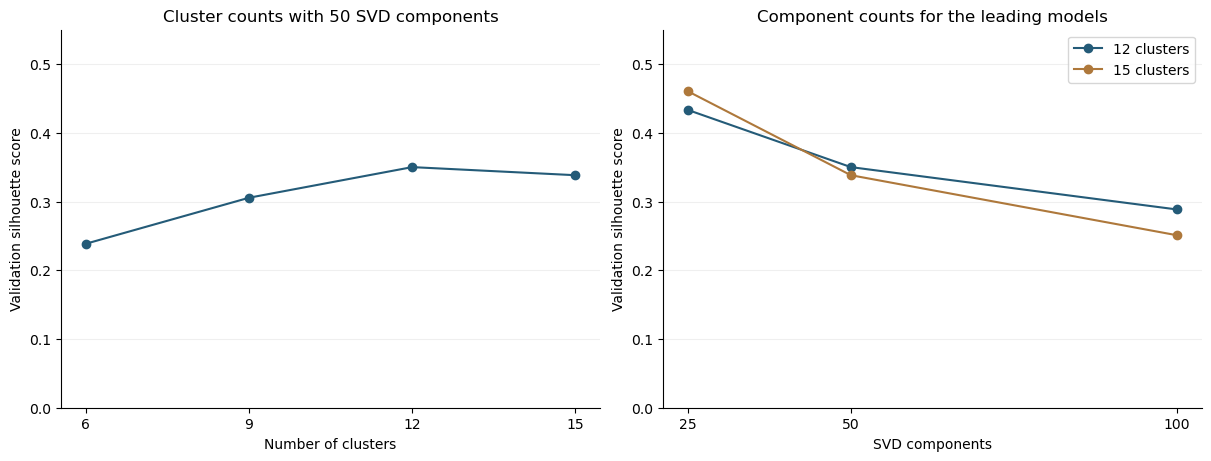

In [63]:
# Visualize the existing validation results without fitting new models.
fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5), layout="constrained"
)

initial = cluster_results.sort_values("Clusters")

axes[0].plot(
    initial["Clusters"],
    initial["Validation silhouette"],
    marker="o",
    color="#245B78"
)

axes[0].set_xticks(initial["Clusters"])
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Validation silhouette score")
axes[0].set_title("Cluster counts with 50 SVD components")

for k, color in [(12, "#245B78"), (15, "#AE783B")]:
    subset = tuning_results[
        tuning_results["Clusters"].eq(k)
    ].sort_values("SVD components")

    axes[1].plot(
        subset["SVD components"],
        subset["Validation silhouette"],
        marker="o",
        color=color,
        label=f"{k} clusters"
    )

axes[1].set_xticks([25, 50, 100])
axes[1].set_xlabel("SVD components")
axes[1].set_ylabel("Validation silhouette score")
axes[1].set_title("Component counts for the leading models")
axes[1].legend()

for ax in axes:
    ax.set_ylim(0, 0.55)
    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.show()

The highest validation silhouette score was 0.460, obtained with 25 SVD components and 15 clusters. Models using 100 components had lower scores and produced some very small clusters. I provisionally select the 25-component, 15-cluster model and inspect its vocabulary and example questions before drawing conclusions about its usefulness.

## Inspect the Cluster Contents

I examine the most frequent words and one example training question from each cluster. Word frequencies are calculated from the original word-count matrix after assigning questions to clusters. This helps assess whether the groups have recognizable themes rather than relying on the silhouette score alone.

In [64]:
# Fit the leading configuration and inspect its training clusters.
selected_svd = TruncatedSVD(n_components=25, random_state=530)
train_reduced = selected_svd.fit_transform(X_train)
valid_reduced = selected_svd.transform(X_valid)

selected_model = MiniBatchKMeans(
    n_clusters=15,
    random_state=530,
    n_init=10,
    batch_size=256
)

train_clusters = selected_model.fit_predict(train_reduced)

clustered_train = train_data.copy()
clustered_train["cluster"] = train_clusters + 1

words = vectorizer.get_feature_names_out()
cluster_summary = []

for cluster in range(1, 16):
    mask = train_clusters == cluster - 1
    word_counts = X_train[mask].sum(axis=0).A1
    top_words = words[word_counts.argsort()[-8:][::-1]]

    cluster_summary.append({
        "Cluster": cluster,
        "Training questions": int(mask.sum()),
        "Frequent words": ", ".join(top_words),
        "Example question": clustered_train.loc[
            clustered_train["cluster"].eq(cluster), "question"
        ].iloc[0]
    })

cluster_summary = pd.DataFrame(cluster_summary)
display(cluster_summary)

,Cluster,Training questions,Frequent words,Example question
0,1,779,"car, insurance, cover, drive, affect, need, co...",Can I Get USAA Car Insurance ?
1,2,1012,"medicare, cover, covered, advantage, plan, ins...",Is Transcranial Magnetic Stimulation Covered B...
2,3,250,"life, insurance, term, policy, year, buy, best...",Which Company Is Best For Term Life Insurance ?
3,4,462,"home, insurance, cover, need, cost, damage, cl...",Can You Write Off Home Insurance On Your Taxes ?
4,5,2347,"life, insurance, policy, buy, best, good, cash...",Why Is Whole Life Insurance More Expensive ?
5,6,332,"plan, retirement, medigap, qualified, best, sa...",What Is The Least Expensive Medigap Plan ?
6,7,824,"insurance, renters, cover, illness, critical, ...",Does Renters Insurance Cover Pet Damage ?
7,8,771,"annuities, medigap, annuity, variable, ira, ro...",What Are The Different Kinds Of Annuities ?
8,9,188,"pay, medicare, home, nursing, care, hospital, ...",Will Medicare Pay For Foot Orthotics ?
9,10,364,"long, insurance, term, care, buy, cover, best,...",Can I Buy Long Term Care Insurance For My Moth...


Several clusters have recognizable themes, including car insurance (1), Medicare (2), life insurance (5), health insurance (11), and disability insurance (12). Clusters 1 and 14 emphasize “car” and “auto,” respectively, while clusters 7 and 8 contain more mixed terminology. These patterns suggest that the model separates both insurance subjects and differences in wording.

### Figure 3. Frequent Words in Selected Training Clusters

I examine clusters 1 and 14 to compare groups emphasizing “car” and “auto,” and clusters 7 and 8 to inspect groups with mixed vocabulary. Each panel shows the eight words appearing in the largest percentage of that cluster’s training questions. These are descriptive examples rather than a summary of all clusters; a question can contain several words, so percentages do not sum to 100%.

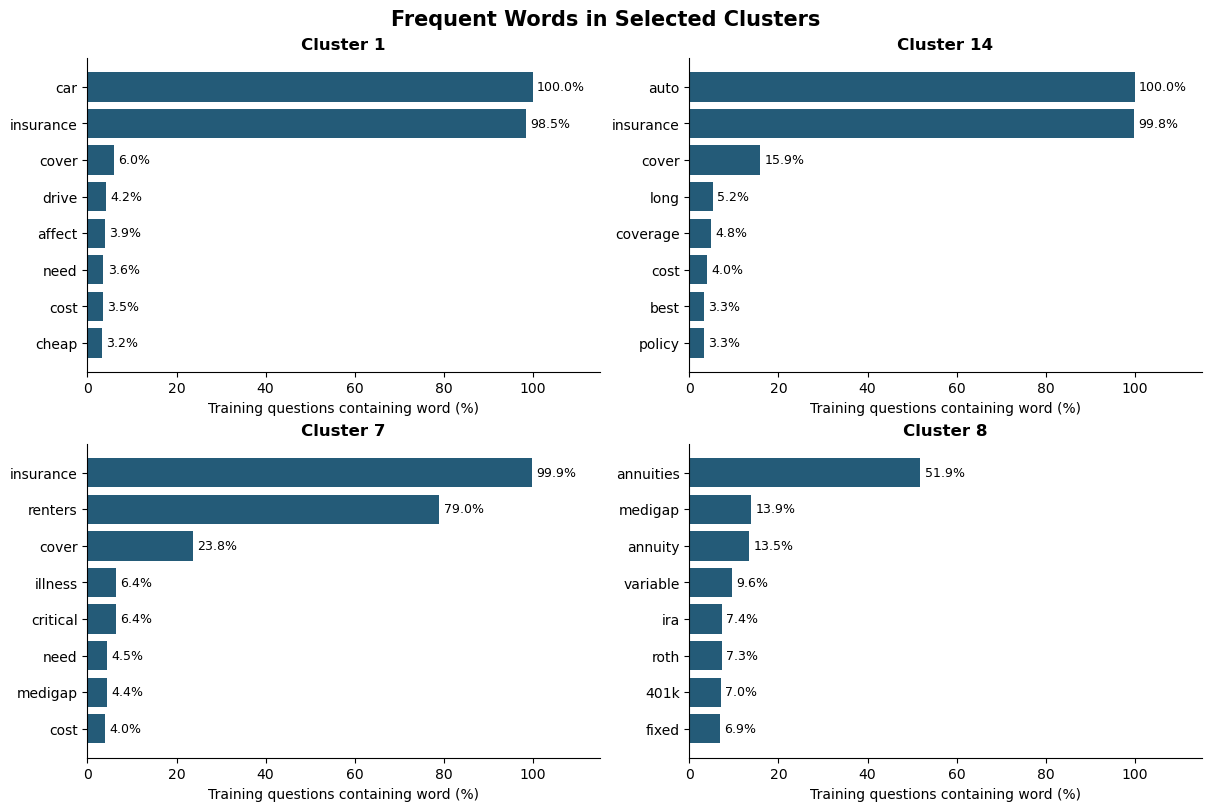

In [65]:
# Compare word presence within four selected training clusters.
fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), layout="constrained"
)

for ax, cluster in zip(axes.flat, [1, 14, 7, 8]):
    mask = train_clusters == cluster - 1

    percentages = (
        100 * (X_train[mask] > 0).sum(axis=0).A1
        / mask.sum()
    )

    top_indices = percentages.argsort()[-8:][::-1]

    bars = ax.barh(
        words[top_indices],
        percentages[top_indices],
        color="#245B78"
    )

    ax.invert_yaxis()
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_xlim(0, 115)
    ax.set_xlabel("Training questions containing word (%)")
    ax.set_title(f"Cluster {cluster}", fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Frequent Words in Selected Clusters",
    fontsize=15,
    fontweight="bold"
)

plt.show()

Clusters 1 and 14 illustrate how wording can separate questions about the same subject: every training question in cluster 1 contains “car,” while every question in cluster 14 contains “auto.” Cluster 7 is dominated by “renters” but also includes “critical” and “illness,” consistent with its mixed category composition. Cluster 8 combines annuity terminology with “medigap,” “IRA,” and “Roth.” These examples show that the model identifies recognizable topics but can also separate synonyms or group questions from different categories.

## Inspect a Simpler Alternative

The 15-cluster model identifies several recognizable insurance topics, but some groups contain similar terminology or mixed subjects. I inspect the 12-cluster alternative using the same 25-component representation to assess whether fewer clusters produce clearer groups. The existing insurance categories remain excluded from model fitting.

In [66]:
# Inspect the simpler model using the same reduced training data.
alternative_model = MiniBatchKMeans(
    n_clusters=12,
    random_state=530,
    n_init=10,
    batch_size=256
)

alternative_clusters = alternative_model.fit_predict(train_reduced)
alternative_summary = []

for cluster in range(1, 13):
    mask = alternative_clusters == cluster - 1
    word_counts = X_train[mask].sum(axis=0).A1
    top_words = words[word_counts.argsort()[-8:][::-1]]

    alternative_summary.append({
        "Cluster": cluster,
        "Training questions": int(mask.sum()),
        "Frequent words": ", ".join(top_words),
        "Example question": train_data.loc[mask, "question"].iloc[0]
    })

alternative_summary = pd.DataFrame(alternative_summary)

# Display full text so the vocabulary and examples can be reviewed.
with pd.option_context("display.max_colwidth", None):
    display(alternative_summary)

,Cluster,Training questions,Frequent words,Example question
0,1,209,"cover, medicare, medigap, plan, dental, care, home, drugs",Does Medicare Cover CPAP Supplies ?
1,2,2583,"life, insurance, policy, term, best, buy, cash, good",Why Is Whole Life Insurance More Expensive ?
2,3,1086,"annuities, retirement, plan, medigap, annuity, variable, 401k, ira",What Are The Different Kinds Of Annuities ?
3,4,381,"long, insurance, term, care, buy, cover, need, best",What Is The Difference Between Long Term Care And Disability Insurance ?
4,5,1152,"insurance, health, cover, cost, pay, best, buy, work",Section 125 Employer Health Insurance Plan What Is It ?
5,6,644,"insurance, renters, cover, need, damage, cost, apartment, buy",Does Renters Insurance Cover Pet Damage ?
6,7,1247,"insurance, car, home, need, cost, cover, illness, critical",Can I Get USAA Car Insurance ?
7,8,559,"disability, insurance, term, long, short, buy, cover, need",What Is The Best Disability Insurance Company ?
8,9,488,"insurance, auto, cover, long, coverage, cost, policy, best",Does auto insurance cover theft ?
9,10,1011,"medicare, pay, covered, advantage, plan, insurance, best, supplement",Is Transcranial Magnetic Stimulation Covered By Medicare ?


## Check Clustering Stability

I repeat the 12- and 15-cluster models with two additional random seeds while keeping the word-count and SVD representations fixed. I compare validation assignments with the original model using the adjusted Rand index (ARI). A value of 1 indicates identical groupings, even if cluster numbers differ; values near 0 indicate agreement similar to chance. This checks sensitivity to clustering initialization.

In [67]:
from sklearn.metrics import adjusted_rand_score

# Check whether different initializations produce similar groups.
stability_results = []

for k, reference_model in [
    (12, alternative_model),
    (15, selected_model)
]:
    reference_labels = reference_model.predict(valid_reduced)

    for seed in [42, 2026]:
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10,
            batch_size=256
        )

        model.fit(train_reduced)
        labels = model.predict(valid_reduced)

        stability_results.append({
            "Clusters": k,
            "Random seed": seed,
            "Validation silhouette": silhouette_score(
                valid_reduced,
                labels,
                sample_size=2000,
                random_state=530
            ),
            "ARI with original model": adjusted_rand_score(
                reference_labels, labels
            )
        })

stability_results = pd.DataFrame(stability_results)
display(stability_results.round(3))

,Clusters,Random seed,Validation silhouette,ARI with original model
0,12,42,0.481,0.894
1,12,2026,0.443,0.858
2,15,42,0.481,0.811
3,15,2026,0.481,0.896


Both cluster counts produced reasonably consistent assignments across random seeds. For the selected 15-cluster model, agreement with the original assignments ranged from 0.811 to 0.896. I retain 15 clusters and 25 SVD components because this configuration had the highest silhouette score in the initial tuning comparison and identified several recognizable topics. Some mixed or overlapping groups remain.

## Evaluate the Selected Model on Test Data

I apply the fitted vectorizer, SVD transformation, and clustering model to the test questions without refitting them. The test silhouette score measures cluster separation on unseen questions. I also compare cluster assignments with the original insurance categories using adjusted Rand index. This second comparison evaluates agreement with existing labels, not prediction accuracy, because the model was trained without those labels.

In [68]:
# Apply the selected model to previously unused test questions.
X_test = vectorizer.transform(test_data["question"])
test_reduced = selected_svd.transform(X_test)
test_clusters = selected_model.predict(test_reduced)

test_silhouette = silhouette_score(
    test_reduced,
    test_clusters,
    sample_size=2000,
    random_state=530
)

category_agreement = adjusted_rand_score(
    test_data["category"],
    test_clusters
)

test_results = pd.DataFrame({
    "Measure": [
        "Test questions",
        "SVD components",
        "Clusters",
        "Test silhouette",
        "ARI with insurance categories"
    ],
    "Value": [
        len(test_data),
        25,
        15,
        round(test_silhouette, 3),
        round(category_agreement, 3)
    ]
})

display(test_results)

# Retain the assignments for the final tables and figures.
clustered_test = test_data.copy()
clustered_test["cluster"] = test_clusters + 1

,Measure,Value
0,Test questions,3373.000
1,SVD components,25.000
2,Clusters,15.000
3,Test silhouette,0.476
4,ARI with insurance categories,0.796


The selected model achieved a silhouette score of 0.476 on 3,373 unseen test questions, compared with 0.460 on the validation set. This suggests that cluster separation was maintained on new questions. Agreement between the test clusters and the original insurance categories was substantial, with an adjusted Rand index of 0.796. Although category labels were excluded from training, the clusters largely reflect existing insurance topics, with some topics divided across multiple groups.

## Compare Clusters with Insurance Categories

I summarize the original category labels within each test cluster. For each group, I report its size, most common category, and the percentage belonging to that category. This identifies groups that closely match an existing topic and groups that contain a mixture of categories.

In [69]:
# Count the original insurance categories within each test cluster.
category_counts = pd.crosstab(
    clustered_test["cluster"],
    clustered_test["category"]
)

cluster_comparison = pd.DataFrame({
    "Test questions": category_counts.sum(axis=1),
    "Most common category": category_counts.idxmax(axis=1),
    "Most common category (%)": (
        100 * category_counts.max(axis=1)
        / category_counts.sum(axis=1)
    ).round(1)
})

cluster_comparison = (
    cluster_comparison.rename_axis("Cluster").reset_index()
)

display(cluster_comparison)

,Cluster,Test questions,Most common category,Most common category (%)
0,1,269,auto-insurance,99.3
1,2,320,medicare-insurance,99.7
2,3,73,life-insurance,100.0
3,4,140,home-insurance,96.4
4,5,799,life-insurance,99.5
5,6,103,retirement-plans,88.3
6,7,290,renters-insurance,69.3
7,8,236,annuities,57.6
8,9,56,medicare-insurance,94.6
9,10,109,long-term-care-insurance,99.1


Most test clusters are strongly concentrated within one existing insurance category. However, some categories are divided into multiple groups, showing that the model also separates vocabulary patterns within a topic. Clusters 7 and 8 are less concentrated: renters insurance accounts for 69.3% of cluster 7, while annuities account for 57.6% of cluster 8. These mixed groups show why the overall agreement score should be considered alongside individual cluster results.

### Figure 4. Cluster Composition and Category Distribution

Panel A shows the category composition of each cluster; rows total approximately 100%. Panel B shows where each category’s questions were assigned; columns total approximately 100%. Both panels use the same test questions and cluster assignments. All nonzero percentages are labeled, with small rounding differences possible.

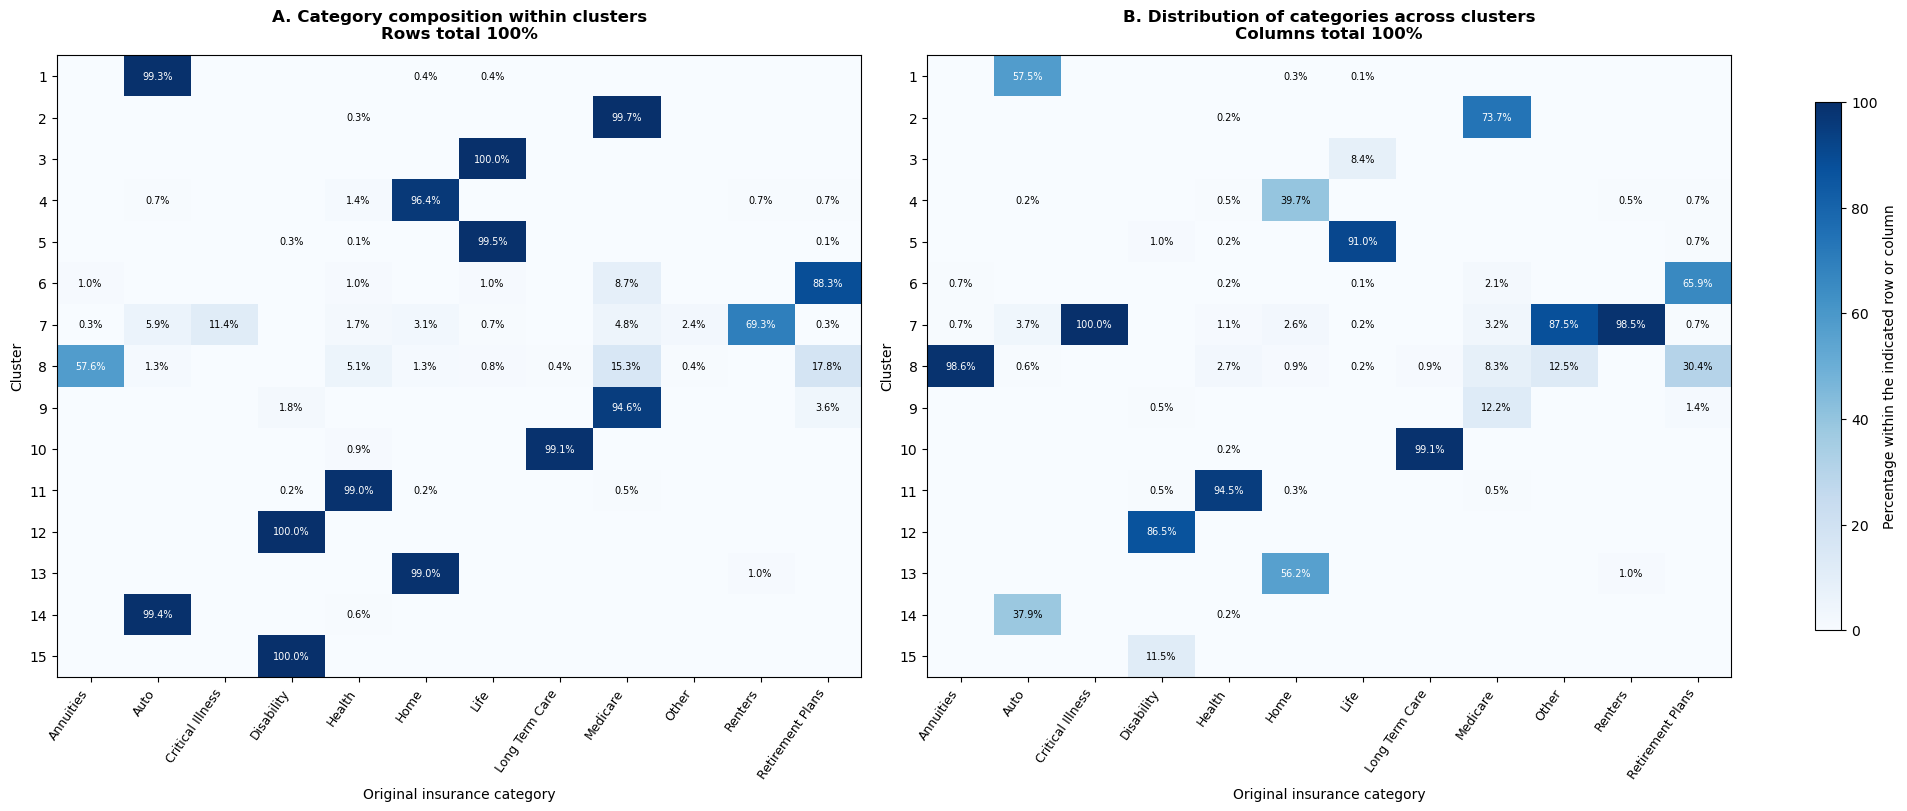

In [72]:
# Compare cluster composition with category distribution.
within_cluster = category_counts.div(
    category_counts.sum(axis=1), axis=0
) * 100

within_category = category_counts.div(
    category_counts.sum(axis=0), axis=1
) * 100

category_labels = [
    category.replace("-insurance", "").replace("-", " ").title()
    for category in category_counts.columns
]

fig, axes = plt.subplots(
    1, 2, figsize=(19, 8), layout="constrained"
)

for ax, values, title in zip(
    axes,
    [within_cluster, within_category],
    [
        "A. Category composition within clusters\nRows total 100%",
        "B. Distribution of categories across clusters\nColumns total 100%"
    ]
):
    image = ax.imshow(
        values,
        cmap="Blues",
        vmin=0,
        vmax=100,
        aspect="auto"
    )

    ax.set_xticks(
        range(len(category_labels)),
        category_labels,
        rotation=55,
        ha="right",
        fontsize=9
    )
    ax.set_yticks(range(len(values)), values.index)
    ax.set_xlabel("Original insurance category")
    ax.set_ylabel("Cluster")
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)

    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values.iloc[row, column]

            if value > 0:
                ax.text(
                    column, row, f"{value:.1f}%",
                    ha="center", va="center",
                    color="white" if value > 50 else "black",
                    fontsize=7
                )

fig.colorbar(
    image,
    ax=axes,
    label="Percentage within the indicated row or column",
    shrink=0.85
)

plt.show()

The panels show that a cluster can contain almost exclusively one category without capturing all questions from that category. Clusters 1 and 14 are each over 99% auto insurance, but contain 57.5% and 37.9% of all auto-insurance test questions, respectively. Their training vocabulary emphasizes “car” and “auto,” illustrating how wording can divide a single subject.

Conversely, a category can remain together without forming a distinct cluster. All critical-illness test questions appear in cluster 7, but represent only 11.4% of that cluster, which is dominated by renters insurance. These findings show why strong overall category agreement does not establish that every topic receives its own useful group.

## Discussion

Text clustering organized many insurance questions into recognizable topics. The selected model used 25 SVD components and 15 clusters, achieving a test silhouette score of 0.476 and an adjusted Rand index of 0.796 against the existing categories. Assignments were also reasonably consistent across random starting points.

The two heatmaps reveal both strengths and limitations. Some categories, such as health and long-term-care insurance, largely form distinct groups. Others, including auto and home insurance, are divided across clusters. Smaller categories can remain together without forming a separate group: all critical-illness test questions appear in cluster 7, but that cluster is dominated by renters insurance.

These results suggest that clustering could help organize insurance FAQs, although mixed groups and wording differences would require human review. Word counts capture vocabulary rather than meaning or word order, and unequal category sizes can obscure smaller topics in overall evaluation scores. A future comparison could examine whether combining synonyms or using a different text representation produces clearer groups.